# Givers, Takers and the Shape of a City

- We model a **city** as a network of citizens who are either **givers** (cooperative strategies) or **takers** (exploitative ones), playing the **Iterated Prisoner's Dilemma** with the people they actually meet.
- We build the city in **five steps (S1 to S5)**, adding one mechanism at a time: from a well-mixed crowd, to a fixed network, to ties that fade, to partners chosen by proximity, habit and status, to a city that replaces the relationships it loses.
- We sweep the **share of givers** from 0 to 1 in every step and ask what happens to **prosperity** (wealth per person), **inequality** (Gini coefficient) and **structure** (who ends up connected to whom).
- What we find: more givers always make a city richer, but the richest cities are not the most equal. Inequality peaks in mixed cities, and it stays high on a network with hubs, where the citizens everyone wants to meet capture the gains.

## Background and Goal

**The phenomenon:** communities of similar size and resources end up in very different places: some generate a lot of wealth and spread it widely, others generate less and concentrate it. Cooperation is part of the story, but its payoff is strongly context-dependent: across 83 studies and 957 estimates, the average effect of social capital on growth is close to zero, with large positive and negative effects in different settings [1]. What seems to matter is *who* is connected to whom: cross-class friendships predict upward mobility, while tight-knit cohesion does not [2].

**Why an agent-based model:** prosperity, inequality and social segregation are outcomes nobody in a city chooses. They emerge from many local interactions, each of which is simple to state. That is the case for simulating individual agents and their interactions rather than writing an equation for the aggregate [3].

**What is uncertain:** whether cooperation also makes a society more equal is contested. Network-game models find inequality falling as cooperation rises [4], [5]; laboratory networks with clustering produce more inequality and rich-poor segregation [6]; and making wealth visible amplifies initial advantage [7].

**Research question:**

> In simulated cities that differ in their mix of cooperative and exploitative agents, what patterns emerge in prosperity, in how that prosperity is distributed, and in who ends up connected to whom?

**Hypotheses:**

| # | Hypothesis | What would refute it |
|---|---|---|
| **H1** | **Prosperity threshold:** wealth per person rises with the share of givers, non-linearly, with a share below which cooperation cannot get established. | Wealth is a straight line in the giver share. |
| **H2** | **Prosperity and equality decouple:** inequality does not simply fall as givers increase; it flattens or rises in the richest cities, because cooperation relies on clusters [8], [9] and popular citizens attract more of the surplus. | Inequality falls steadily with the giver share on every network. |
| **H3** | **Emergent segregation:** givers end up tied to givers and takers are pushed to the edges, with no rule telling anyone to avoid anyone. | Class assortativity stays flat and takers keep giver-level ties. |
| **H4** | **The poverty trap is equal:** taker-dominated cities are poor but not unequal, so median wealth separates good cities from bad better than inequality does. | Taker-dominated cities are markedly unequal. |

H2 runs against the existing model results, so either answer is informative.

## The Model

### Citizens and the game

Every agent keeps one fixed strategy for the whole run. Each meeting is one round of the Prisoner's Dilemma, with the payoffs `(T, R, P, S) = (5, 3, 1, 0)` used in [3, Ch. 12]:

| | Opponent cooperates | Opponent defects |
|---|---|---|
| **You cooperate** | 3 | 0 |
| **You defect** | 5 | 1 |

Because `2R = 6 > T + S = 5 > 2P = 2`, a cooperating pair **creates** more wealth than an exploitative pair, which creates more than a mutually defecting pair. Wealth is created by interaction, not moved between agents, so a city's total wealth reports how its citizens have treated each other.

| Strategy | Behaviour | Class |
|---|---|---|
| **AllC** | Always cooperates. | Giver |
| **TFT** | Cooperates first, then copies the partner's last move. | Giver |
| **GTFT** | TFT, but forgives a defection with probability 0.1. | Giver |
| **TF2T** | Defects only after two defections in a row. | Giver |
| **Grudger** | Cooperates until the first defection, then defects forever. | Giver |
| **Pavlov** | Repeats its last move if it scored well, switches if not. | Giver |
| **AllD** | Always defects. | Taker |
| **Random** | Cooperates with probability 0.5. | Taker |

The **giver fraction** `f` is the share of agents drawn from the giver class; the mix within each class is fixed, so one number describes a city's population.

### Terms

- **Tie:** an acquaintance relationship, with a **strength** that grows with use and fades without it. A tie is not a meeting: having a tie means these two know each other.
- **Meeting:** one interaction in one round, which is one game of the Prisoner's Dilemma. Each agent starts one meeting per round and may be chosen by others.
- **Tie capacity:** the number of ties an agent may hold, fixed at its degree in the starting network, so a city keeps its degree distribution as ties break and form.
- **Popularity rating:** a bounded, slow-moving score of how cooperative and well-connected an agent has been. It is a coarse public signal, not perfect information.
- **Giver-dominated / taker-dominated:** cities with `f >= 0.7` and `f <= 0.3`.

### One round

```
for each round t in 1..T:
    1. every agent picks a partner        (proximity x habit x popularity)
    2. each pair plays one game           (each strategy sees its history with that partner)
    3. payoffs are added to wealth
    4. ties used this round get stronger
    5. unused ties decay with time since contact
    6. ties below the severance threshold break
    7. agents with spare capacity form new ties (friends of friends)
    8. popularity ratings update
```

Updating is synchronous: every choice in a round uses the state at the start of that round.

### The three rules that decide behaviour

Everything the model does comes from three rules. Each one is given in symbols, then in plain
words, with the numbers we actually use.

**Rule 1: who meets whom**

Each week every citizen picks one person to meet, and not at random. Every possible partner `j`
gets a score, and the chance of picking them is their score divided by the total of all the
scores:

$$ s_{ij} = \underbrace{(w_{ij} + \varepsilon)^{\beta}}_{\text{habit}} \times \underbrace{R_j^{\gamma}}_{\text{standing}} \times \underbrace{d_{ij}^{-\lambda}}_{\text{closeness}} $$

- **Habit**, $w_{ij}$: how strong the relationship between `i` and `j` already is. Someone you
  see often scores higher. The small amount $\varepsilon = 0.1$ is added to everybody's score so
  that a person you have never met still has some chance of being picked. Without it no new
  relationship could ever start.
- **Standing**, $R_j$: how popular `j` is, a number between 0.1 and 1 defined in rule 3.
- **Closeness**, $d_{ij}$: how many handshakes away `j` is. A neighbour is 1 away and scores
  $1^{-1} = 1$. A friend of a friend is 2 away and scores $2^{-1} = 0.5$, so is half as likely,
  everything else being equal. We never look further than 3 handshakes. This $1/d$ shape is how
  the chance of a real social tie falls off with distance [10].
- The exponents $\beta$, $\gamma$ and $\lambda$ say how much each of the three counts. All are 1
  here, so the three count equally, and setting one to 0 switches that influence off. That is how
  the five steps below are built.
- **A worked example:** a well-liked neighbour you already see often ($w = 5$, $R = 0.9$,
  $d = 1$) scores $5.1 \times 0.9 \times 1 = 4.6$. A poorly rated stranger two handshakes away
  ($w = 0$, $R = 0.2$, $d = 2$) scores $0.1 \times 0.2 \times 0.5 = 0.01$. The neighbour is about
  450 times likelier to be chosen.
- Other people are choosing too, so a citizen can be picked by several in one week. The number of
  meetings anyone can **receive** is capped at $c_{max} = 4$ a week: attention is finite, and
  without a cap the most popular person soaks up an unlimited share of the city's meetings.

**Rule 2: relationships strengthen, fade and break**

- Every meeting adds $\delta = 1$ to the strength of that relationship.
- Strength fades with the time since the last meeting, $w \times e^{-\alpha \Delta t}$, at
  $\alpha = 0.05$ per week. This is **neglect, not punishment**: a relationship fades because it
  goes unused, whatever happened the last time the two met [11].
- When strength falls below $\theta = 0.1$ the relationship is dropped. Starting from a single
  meeting, that takes $\ln(10) / 0.05 \approx 46$ weeks without contact.
- A relationship is judged on **its own** strength, not against a better offer. Judging by
  comparison would freeze the city: someone you have never met has strength near 0, so they could
  never beat someone you already know.

**Rule 3: popularity, meaning how visible and well regarded someone is**

Each citizen carries a single number, their rating, standing for how good they are to meet. It is
built from two things any real citizen could notice:

- **How cooperative they have been lately**, $\kappa_j$: the share of their recent moves that
  were cooperative. It is a slow-moving average, so one bad week does not destroy a reputation
  and one good week does not make one.
- **How connected they are**, $s_j$: the total strength of all their relationships, divided by
  the largest total in the city. The best-connected citizen scores 1 and a recluse scores near 0.

$$ R_j = R_{min} + (R_{max} - R_{min}) \times \kappa_j \times s_j = 0.1 + 0.9 \times \kappa_j \times s_j $$

The two are multiplied, so a citizen needs both: a cooperative hermit and a well-connected
defector both end up with a low rating. The answer is then squeezed into the range 0.1 to 1. The
floor of 0.1 matters, because it means nobody is ever literally unreachable, only unlikely to be
chosen.

This rating is the only thing a citizen knows about someone they have not met, and it is kept
coarse and slow: citizens respond to a rough social signal, not to perfect information about each
other. No rule anywhere says to avoid a taker. If takers end up
isolated, it is only because defecting lowers their rating, a lower rating means being chosen
less often, and a relationship nobody uses fades and is dropped.

## Scenarios: What We Run and What to Expect

Each step adds one mechanism to the one before it. Every step chooses partners with the same sampling rule, so **each step reproduces the previous one exactly, with the same seed, when its new mechanism is switched off**. That is the main correctness check, and it means any change in behaviour can be attributed to the mechanism just added.

| ID | Network | Who you can meet | Ties | Rewiring | What it represents |
|:--:|---|---|---|:--:|---|
| **S1** | complete | anyone in the city, uniformly | none | n/a | A well-mixed crowd: the mean-field baseline |
| **S2** | Erdős–Rényi | your neighbours, uniformly | permanent | No | Structure alone: repeated local interaction |
| **S3** | Erdős–Rényi | your neighbours, uniformly | decay and severance | No | Neglect: relationships fade without contact |
| **S4** | Erdős–Rényi | anyone within 3 hops, by proximity x habit x popularity | decay and severance | No | Choice: who you meet depends on distance, habit and status |
| **S5** | Erdős–Rényi | as S4 | decay and severance | Yes | The full city: lost relationships are replaced |
| **S5b** | Barabási–Albert | as S4 | decay and severance | Yes | The full city on a scale-free network, which has hubs |

**What to expect, and why:**

- **S1, well-mixed:** takers do well: a taker meets a new partner almost every round, so retaliation rarely lands on the agent that earned it. Wealth should rise with the giver share, and inequality should be low, because nobody has a structural advantage.
- **S2, static network:** repeated meetings with the same neighbours let reciprocal strategies recognise and punish takers, which is network reciprocity [8]. Expect the taker advantage to shrink and inequality to rise above S1, since a citizen's fate now depends on the neighbours they happen to have.
- **S3, ties fade:** with the default decay rate a tie played every few rounds never fades, so expect S3 to look much like S2. Decay cannot tell a giver from a taker here, because partners are still drawn uniformly.
- **S4, chosen partners:** this is where classes should separate. Cooperative agents earn higher ratings, are chosen more often and play more games, so expect givers to pull ahead, inequality to rise, and takers to lose ties.
- **S5, the full city:** refilling severed ties should keep the network in one piece without changing who prospers, since new ties are drawn by the same rule that favoured the same people.
- **S5b, scale-free:** hubs start with many more ties than anyone else and attract more meetings, so expect the highest inequality and the clearest case of prosperity and equality moving apart.

## Protocol and Assumptions

**Runs:**

1. `N = 100` agents per city, `T = 500` rounds. One round is read as a week.
2. **8 seeds** per point, and the giver fraction `f` takes the values 0, 0.2, 0.4, 0.6, 0.8, 1.0.
3. The same seeds are used in every scenario, so differences come from the rules rather than from the draw.
4. Every stochastic step draws from one seeded `numpy` generator passed through the model. There is no global random state, so a run is reproducible from its seed and configuration.
5. Cities start with zero wealth and a uniform small weight on every tie, so nobody begins privileged.

**Measures**, all taken at the end of the run unless stated:

| Measure | Definition |
|---|---|
| **Wealth per person** | Mean accumulated payoff. Prosperity. |
| **Median wealth** | The typical citizen, which falls below the mean when gains concentrate. |
| **Gini coefficient** | Inequality of accumulated wealth: 0 is everyone equal, 1 is one agent holding everything. |
| **Cooperation rate** | Share of all moves that were cooperative, averaged over the last 100 rounds. |
| **Taker payoff gap** | Taker minus giver payoff per game. Positive means exploitation pays. |
| **Class assortativity** | Correlation of class across ties: positive means givers tie to givers, negative means the classes mix. |
| **Realised partners** | Distinct agents an individual actually played in the last 100 rounds. |
| **Noise floor** | Gini of a city where everyone plays the same strategy, so any inequality comes from luck and network position alone. |

**Assumptions:** strategies never change or learn; agents cannot refuse a game; wealth is never spent or lost; and every city is closed, with no birth, death or migration.

## Parameter Reference

Values used in every run below. The model exposes each as a configuration key, and alternatives listed in the right-hand column can be selected without changing code.

| Symbol | Config key | Meaning | Value here | Alternatives available |
|---|---|---|---|---|
| `N` | `population.n_agents` | agents per city | 100 | any |
| `T` | `run.n_rounds` | rounds per run | 500 | any |
| `f` | `population.giver_fraction` | share of givers | 0 to 1, step 0.2 | any |
| `k` | `topology.mean_degree` | mean degree of the starting network | 6 | any |
| | `topology.name` | starting network | `erdos_renyi`, `barabasi_albert` | `watts_strogatz`, `complete` |
| `(T,R,P,S)` | `game.payoff` | payoff matrix | (5, 3, 1, 0) | any ordering |
| `rho` | `game.rho` | resource density, a payoff multiplier | 1.0 | any |
| `c` | `game.subsistence_cost` | wealth deducted per agent per round | 0.0 | any |
| `nu` | `game.noise` | chance an intended move is flipped | 0.0 | any |
| `B` | `encounter.initiated` | meetings each agent starts per round | 1 | any |
| `c_max` | `encounter.max_received` | cap on meetings received per round | 4 | any, or no cap |
| `d_max` | `encounter.d_max` | furthest candidate partner, in hops | 3 | any |
| `lambda` | `encounter.distance_exponent` | pull of proximity | 1.0 | any; rank-based form |
| `beta` | `encounter.weight_exponent` | pull of habit | 1.0 | any |
| `gamma` | `encounter.popularity_exponent` | pull of status | 1.0 | any |
| `eps` | `encounter.eps` | offset allowing contact without a tie | 0.1 | any |
| `alpha` | `ties.decay_rate` | tie decay per round | 0.05 | any |
| `theta` | `ties.severance_threshold` | ties below this break | 0.1 | any |
| `delta` | `ties.reinforcement` | weight added per meeting | 1.0 | any |
| `R_min`, `R_max` | `popularity.r_min`, `r_max` | rating bounds | 0.1, 1.0 | any |
| `eta` | `popularity.smoothing` | smoothing of the cooperation average | 0.1 | any |
| | `popularity.rule` | what the rating rewards | `behaviour_x_strength` | `behaviour`, `strength` |
| | `ties.severance_rule` | how ties break | `absolute` | `none` |
| | `rewiring.rule` | how freed capacity is refilled | `local_refill` | `none` |
| `n_s` | seeds per point | repeats | 8 | any |

The decay rate, threshold, cap and offset were fixed by a calibration sweep that asked which settings keep a 50/50 city away from the extremes of total collapse and total cooperation.

In [1]:
# One BLAS thread per process: the sweep runs whole cities in parallel, so threads underneath
# them only contend. This must happen before numpy is imported.
import os
for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(_var, "1")

from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "source").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from source import metrics
from source.presets import stage
from source.simulation import Simulation
from utilities import plotting as P
from utilities import runs as R
from utilities.checks import check, same_run, trace

P.use_style()
print(f"python {sys.version.split()[0]} | numpy {np.__version__} | networkx {nx.__version__} | pandas {pd.__version__}")

python 3.12.3 | numpy 2.5.3 | networkx 3.6.1 | pandas 3.0.6


## Checks

Before reading any result, each step must reproduce the step before it when its new mechanism is switched off, and the bookkeeping must hold. These run on small, short cities.

In [2]:
small = {"population.n_agents": 60, "run.n_rounds": 120}

# S3 without decay or severance is S2; S5 without severance is S4. Identical agent by agent.
s2 = trace(Simulation(stage("M1", **small), root_seed=5, repeat=0))
s3_off = trace(Simulation(stage("M2", **{**small, "ties.decay_rate": 0.0, "ties.severance_threshold": 0.0}), root_seed=5, repeat=0))
check(same_run(s2, s3_off), "S3 with no decay and no severance reproduces S2 exactly")

s4 = trace(Simulation(stage("M3", **{**small, "ties.severance_threshold": 0.0}), root_seed=8, repeat=0))
s5_off = trace(Simulation(stage("M4", **{**small, "ties.severance_threshold": 0.0}), root_seed=8, repeat=0))
check(same_run(s4, s5_off), "S5 with no severance reproduces S4 exactly")

sim = Simulation(stage("M4", **small), root_seed=8, repeat=1, instruments=("core",))
out = sim.run().outputs["core"]
s = sim.state
check(np.isclose(s.wealth.sum(), s.payoff_total.sum()), "every unit of wealth comes from a game payoff")
check((s.degree() <= s.capacity).all(), "no agent holds more ties than its capacity")
check(np.array_equal(s.adjacency, s.adjacency.T) and not s.adjacency.diagonal().any(), "ties are mutual, and nobody is tied to themselves")
check(out["max_received"].max() <= stage("M4").encounter.max_received, "no agent is met more often than the cap allows")

PASS  S3 with no decay and no severance reproduces S2 exactly
PASS  S5 with no severance reproduces S4 exactly
PASS  every unit of wealth comes from a game payoff
PASS  no agent holds more ties than its capacity
PASS  ties are mutual, and nobody is tied to themselves
PASS  no agent is met more often than the cap allows


## One City, Watched for 500 Weeks

A single mixed city (`f = 0.5`) on the full model, to see what the rules produce before comparing scenarios. Node colour is strategy, node size is wealth, and edge width is tie strength.

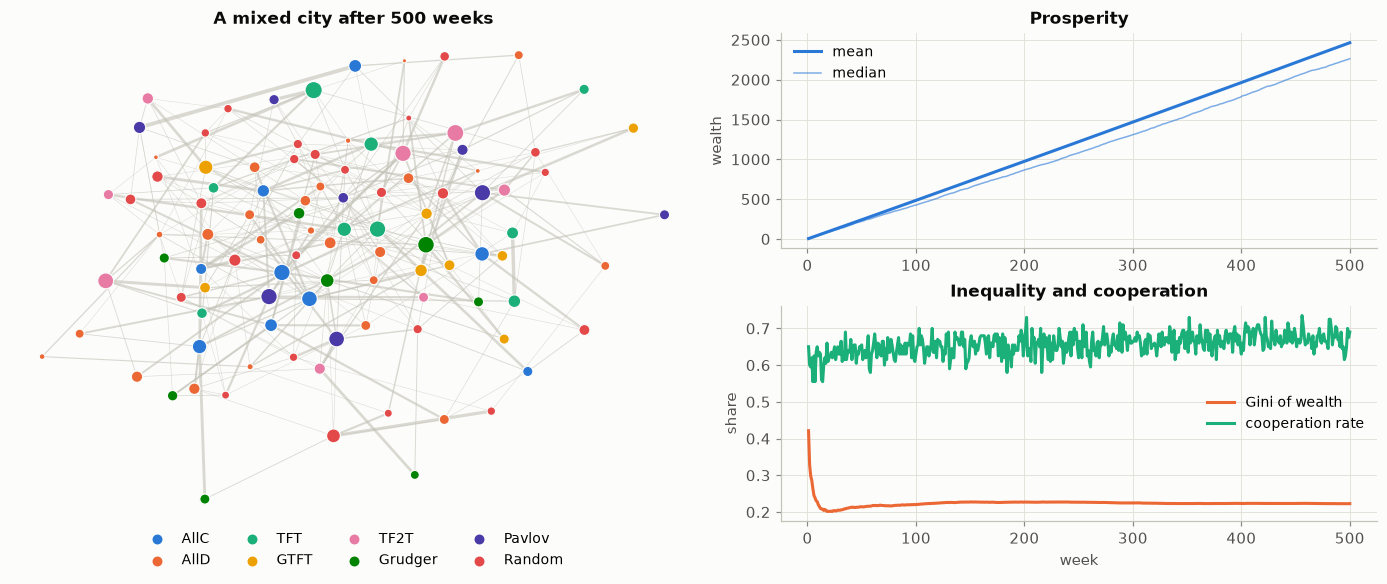

mean wealth 2464 | median 2264 | Gini 0.223
givers 3065 | takers 1863


In [3]:
from utilities.network_draw import draw_snapshot, layout, strategy_legend

city = Simulation(stage("M4", **{"population.n_agents": 100, "run.n_rounds": 500, "population.giver_fraction": 0.5}),
                  root_seed=R.DEFAULT_SEED, repeat=0, instruments=("core", "snapshot"))
result = city.run()
core, snap = result.outputs["core"], result.outputs["snapshot"]

fig = plt.figure(figsize=(12.5, 5.2))
grid = fig.add_gridspec(2, 2, width_ratios=[1.15, 1])
ax_net = fig.add_subplot(grid[:, 0])
draw_snapshot(ax_net, snap, layout(snap["adjacency"], seed=7), title="A mixed city after 500 weeks")
strategy_legend(ax_net)

ax_top, ax_bottom = fig.add_subplot(grid[0, 1]), fig.add_subplot(grid[1, 1])
weeks = np.arange(1, len(core["gini"]) + 1)
ax_top.plot(weeks, core["mean_wealth"], color=P.SERIES[0], label="mean")
ax_top.plot(weeks, core["median_wealth"], color=P.SERIES[0], linewidth=1, alpha=0.6, label="median")
ax_top.set(ylabel="wealth", title="Prosperity")
ax_top.legend(loc="upper left")
ax_bottom.plot(weeks, core["gini"], color=P.SERIES[1], label="Gini of wealth")
ax_bottom.plot(weeks, core["coop_rate"], color=P.SERIES[2], label="cooperation rate")
ax_bottom.set(xlabel="week", ylabel="share", title="Inequality and cooperation")
ax_bottom.legend(loc="center right")
plt.show()

wealth = city.state.wealth
print(f"mean wealth {wealth.mean():.0f} | median {np.median(wealth):.0f} | Gini {metrics.gini(wealth):.3f}")
print(f"givers {wealth[city.state.giver].mean():.0f} | takers {wealth[~city.state.giver].mean():.0f}")

**What happens:** wealth accumulates steadily and the cooperation rate settles within about 100 weeks. The Gini coefficient spikes early, when a few lucky agents have banked almost everything that exists, then falls and levels off once every citizen has a history. The mean pulls away from the median, which is the signature of gains concentrating on some citizens rather than all.

## Experiment: Sweeping the Mix of Givers and Takers

Every scenario, at six giver fractions, with eight seeds each: 288 cities. Each run takes about two seconds, and they run in parallel, so the whole sweep takes about a minute.

In [4]:
SCENARIOS = {
    "S1 well-mixed":     ("M0", {}),
    "S2 static network": ("M1", {}),
    "S3 ties fade":      ("M2", {}),
    "S4 chosen partners": ("M3", {}),
    "S5 full city":      ("M4", {}),
    "S5b scale-free":    ("M4", {"topology.name": "barabasi_albert"}),
}
FRACTIONS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
SETTINGS = {"population.n_agents": 100, "run.n_rounds": 500}

sweep = R.sweep(SCENARIOS, FRACTIONS, n_seeds=8, timeseries=True, **SETTINGS)
runs = sweep.runs
print(f"{len(runs)} cities: {runs['scenario'].nunique()} scenarios x {len(FRACTIONS)} giver fractions x 8 seeds")
print(f"histories kept: {len(sweep.core):,} core rows, {len(sweep.structure):,} structure rows")
runs.head(3)

288 cities: 6 scenarios x 6 giver fractions x 8 seeds
histories kept: 28,800 core rows, 14,688 structure rows


,scenario,repeat,giver_fraction,topology,mean_wealth,median_wealth,total_wealth,mean_income,gini,top10_share,...,isolated_giver,isolated_taker,clustering,clustering_giver,clustering_taker,transitivity,mean_path_length,n_components,largest_component_share,assortativity_slope
0,S1 well-mixed,0,0.0,complete,1692.62,1686.0,169262.0,3.3980,0.105469,0.124824,...,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0,1.0,NaN
1,S1 well-mixed,1,0.0,complete,1689.42,1642.5,168942.0,3.3882,0.106915,0.124552,...,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0,1.0,NaN
2,S1 well-mixed,2,0.0,complete,1682.70,1671.0,168270.0,3.3504,0.108695,0.126351,...,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0,1.0,NaN


### Prosperity, Inequality and Cooperation

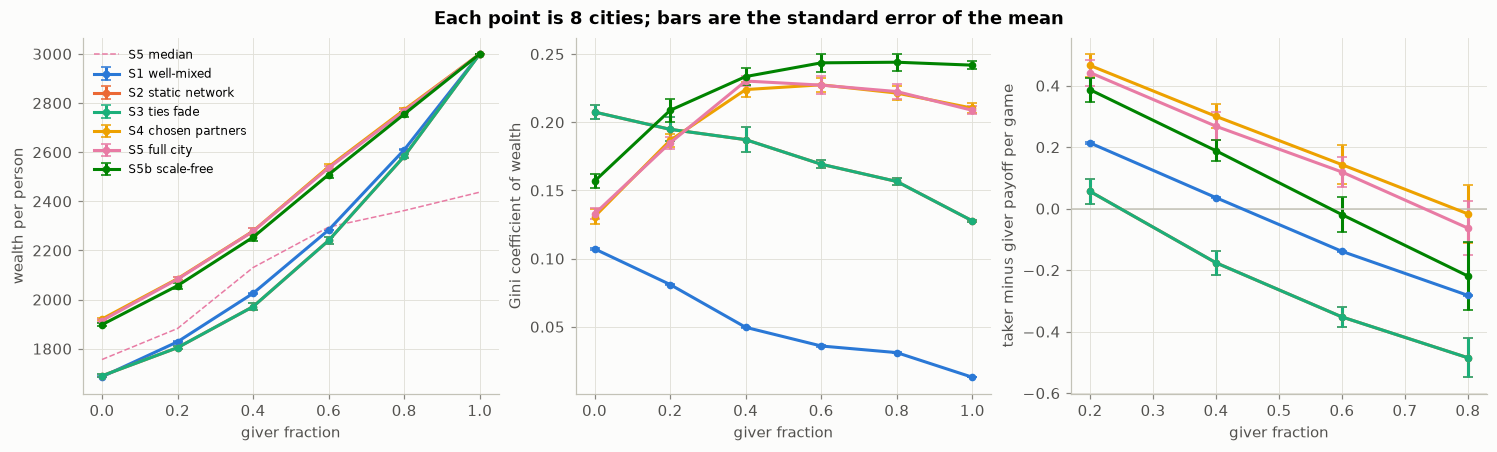

gini                                 \
scenario       S1 well-mixed S2 static network S3 ties fade   
giver_fraction                                                
0.0                    0.107             0.207        0.207   
0.2                    0.081             0.195        0.195   
0.4                    0.050             0.187        0.187   
0.6                    0.036             0.169        0.169   
0.8                    0.031             0.157        0.157   
1.0                    0.013             0.128        0.128   

                                                                mean_wealth  \
scenario       S4 chosen partners S5 full city S5b scale-free S1 well-mixed   
giver_fraction                                                                
0.0                         0.131        0.133          0.157      1685.735   
0.2                         0.187        0.185          0.209      1828.165   
0.4                         0.224        0.230          0.234      2025.530   
0.6                         0.227        0.227          0.244      2283.496   
0.8                         0.221        0.223          0.244      2609.774   
1.0                         0.210        0.209          0.242      3000.000   

                                                                               \
scenario       S2 static network S3 ties fade S4 chosen partners S5 full city   
giver_fraction                                                                  
0.0                     1689.615     1689.615           1920.779     1914.348   
0.2                     1804.310     1804.310           2085.024     2083.004   
0.4                     1971.286     1971.286           2278.780     2277.879   
0.6                     2240.650     2240.650           2540.511     2535.982   
0.8                     2583.334     2583.334           2772.541     2767.324   
1.0                     3000.000     3000.000           3000.000     3000.000   

                               
scenario       S5b scale-free  
giver_fraction                 
0.0                  1897.704  
0.2                  2056.545  
0.4                  2254.002  
0.6                  2508.950  
0.8                  2754.814  
1.0                  3000.000

In [5]:
means = R.cell_means(runs, ["mean_wealth", "median_wealth", "gini", "coop_rate", "payoff_gap"])
colours = dict(zip(SCENARIOS, P.SERIES))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4))
panels = [("mean_wealth", "wealth per person"), ("gini", "Gini coefficient of wealth"),
          ("payoff_gap", "taker minus giver payoff per game")]
for ax, (metric, label) in zip(axes, panels):
    for name in SCENARIOS:
        rows = means[means["scenario"] == name]
        ax.errorbar(rows["giver_fraction"], rows[metric], yerr=rows[f"{metric}_se"],
                    color=colours[name], marker="o", markersize=4, capsize=3, label=name)
    ax.set(xlabel="giver fraction", ylabel=label)
axes[0].plot(means[means["scenario"] == "S5 full city"]["giver_fraction"],
             means[means["scenario"] == "S5 full city"]["median_wealth"],
             color=colours["S5 full city"], linewidth=1, linestyle="--", label="S5 median")
axes[2].axhline(0, color=P.AXIS, linewidth=1)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Each point is 8 cities; bars are the standard error of the mean", fontweight="bold")
plt.show()

means.pivot_table(index="giver_fraction", columns="scenario", values=["mean_wealth", "gini"]).round(3)

### Who Ends Up Connected to Whom

S2 and S3 produce identical cities, so only one of their two lines is visible below.

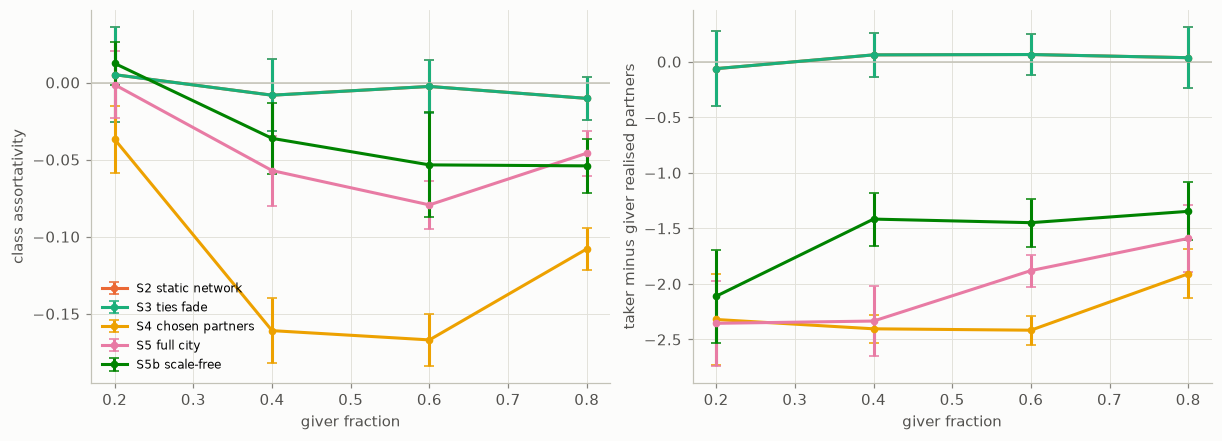

assortativity_class                                 \
scenario             S1 well-mixed S2 static network S3 ties fade   
giver_fraction                                                      
0.2                          -0.01             0.005        0.005   
0.4                          -0.01            -0.008       -0.008   
0.6                          -0.01            -0.003       -0.003   
0.8                          -0.01            -0.010       -0.010   

                                                                partner_gap  \
scenario       S4 chosen partners S5 full city S5b scale-free S1 well-mixed   
giver_fraction                                                                
0.2                        -0.037       -0.001          0.012         0.195   
0.4                        -0.161       -0.057         -0.036        -0.422   
0.6                        -0.167       -0.079         -0.053         0.281   
0.8                        -0.108       -0.046         -0.054         0.217   

                                                                               \
scenario       S2 static network S3 ties fade S4 chosen partners S5 full city   
giver_fraction                                                                  
0.2                       -0.062       -0.062             -2.320       -2.355   
0.4                        0.061        0.061             -2.404       -2.334   
0.6                        0.065        0.065             -2.417       -1.880   
0.8                        0.036        0.036             -1.909       -1.591   

                               
scenario       S5b scale-free  
giver_fraction                 
0.2                    -2.111  
0.4                    -1.417  
0.6                    -1.449  
0.8                    -1.347

In [6]:
structure = runs.assign(partner_gap=runs["realised_degree_taker"] - runs["realised_degree_giver"],
                        weight_gap=runs["weight_taker"] - runs["weight_giver"])
mixed = structure[structure["giver_fraction"].between(0.15, 0.85)]
struct_means = R.cell_means(mixed, ["assortativity_class", "partner_gap", "weight_gap"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for ax, (metric, label) in zip(axes, [("assortativity_class", "class assortativity"),
                                      ("partner_gap", "taker minus giver realised partners")]):
    for name in ["S2 static network", "S3 ties fade", "S4 chosen partners", "S5 full city", "S5b scale-free"]:
        rows = struct_means[struct_means["scenario"] == name]
        ax.errorbar(rows["giver_fraction"], rows[metric], yerr=rows[f"{metric}_se"],
                    color=colours[name], marker="o", markersize=4, capsize=3, label=name)
    ax.axhline(0, color=P.AXIS, linewidth=1)
    ax.set(xlabel="giver fraction", ylabel=label)
axes[0].legend(fontsize=8, loc="lower left")
plt.show()

struct_means.pivot_table(index="giver_fraction", columns="scenario",
                         values=["assortativity_class", "partner_gap"]).round(3)

### How Unequal Is a City That Cannot Be Unfair?

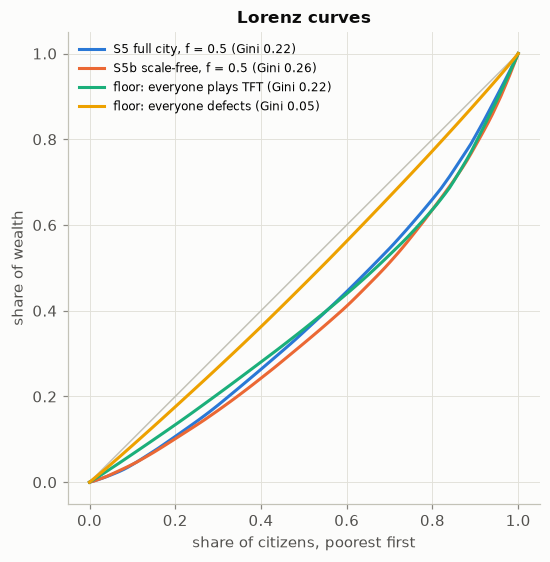

In [7]:
tft_only = {"population.giver_fraction": 1.0, "population.giver_composition": {"tft": 1.0}}
alld_only = {"population.giver_fraction": 0.0, "population.taker_composition": {"alld": 1.0}}
lorenz_curves, floor_gini = {}, {}
for label, base, overrides in [("S5 full city, f = 0.5", "M4", {"population.giver_fraction": 0.5}),
                               ("S5b scale-free, f = 0.5", "M4", {"population.giver_fraction": 0.5, "topology.name": "barabasi_albert"}),
                               ("floor: everyone plays TFT", "M4", tft_only),
                               ("floor: everyone defects", "M4", alld_only)]:
    sim = Simulation(stage(base, **{**SETTINGS, **overrides}), root_seed=R.DEFAULT_SEED, repeat=0, instruments=("core",))
    sim.run()
    lorenz_curves[label] = metrics.lorenz(sim.state.wealth)
    floor_gini[label] = metrics.gini(sim.state.wealth)

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], color=P.AXIS, linewidth=1)
for (label, (p, l)), colour in zip(lorenz_curves.items(), P.SERIES):
    ax.plot(p, l, color=colour, label=f"{label} (Gini {floor_gini[label]:.2f})")
ax.set(xlabel="share of citizens, poorest first", ylabel="share of wealth", title="Lorenz curves")
ax.legend(fontsize=8, loc="upper left")
ax.set_aspect("equal")
plt.show()

**What this shows:** a city where every agent plays TFT, so no game is ever exploited, is just as unequal as the mixed city (Gini 0.22 in both). We did not expect that. A city where everyone defects is far more equal, because there is almost nothing to be unequal about. So the inequality in a mixed city is not the visible mark of exploitation: it is **positional**, produced by who gets met and how often. What the mix of givers and takers changes is *who* ends up poor, and how much wealth exists to divide. What changes the level of inequality is the network: the scale-free city, with its hubs, sits above both.

## Results and Discussion

### What the plots show

**Prosperity (H1):** wealth per person rises with the giver share in every scenario, from roughly 1,700 to 3,000. The rise is not a straight line: it is shallow while takers dominate and steeper once givers are common, because an extra giver only creates surplus when there is another giver to meet. In the well-mixed city (S1), inequality is the lowest of any scenario at every mix, since meeting everyone with equal probability gives no citizen a structural edge.

**Structure changes who wins (S1 to S2):** putting the same population on a fixed network raises inequality sharply and turns the taker payoff advantage negative at moderate giver shares: with repeated meetings, reciprocal strategies punish the takers they can recognise. This is network reciprocity, and it is visible as the gap between the S1 and S2 curves.

**Neglect alone has no effect here (S2 to S3):** not one tie breaks in any S3 city: with about six neighbours and a meeting every week, a tie is used long before it could decay past the threshold. Wealth, cooperation and inequality are therefore identical to S2, run for run; only the tie strengths differ, because decay keeps them bounded instead of letting them accumulate indefinitely. Decay also cannot tell a giver from a taker while partners are drawn uniformly.

**Choice separates the classes (S3 to S4):** once meetings depend on proximity, habit and popularity, inequality rises by about a fifth at `f = 0.4` and by about 40% at `f = 0.6` and above, and takers end with about two fewer realised partners than givers out of roughly ten. Most of the inequality in the full model appears at this step.

**Rewiring repairs without redistributing (S4 to S5):** refilling severed ties leaves wealth, cooperation and inequality within a few percent of S4, because new ties are drawn by the same rule that already favoured the same citizens. It does halve the class disassortativity, since a refilled tie is a fresh draw rather than a surviving habit.

**Hubs concentrate the gains (S5b):** on the scale-free network inequality is the highest of any scenario and stays high in giver-dominated cities, where the other networks are becoming more equal again.

### Why these patterns make sense

1. **Cooperation is a joint product:** two givers create six units of wealth; a giver and a taker create five, most of it going to the taker; two takers create two. Prosperity therefore tracks the *rate of giver-giver meetings*, which grows faster than the giver share itself. That is the threshold in H1.

2. **Inequality needs a mechanism, and here it is access:** in the well-mixed city everyone meets everyone, and inequality stays near the noise floor. Adding a network, then habit, then status, each narrows who a citizen can reach, and each raises inequality. The gains of cooperation flow to whoever is met most.

3. **Takers are not shunned, they are dropped by each other:** class assortativity is negative, not positive: the popularity rating points everyone, takers included, towards cooperative givers, and givers cannot refuse. Ties between two takers are the ones nobody uses, so they decay and break. Takers end up clinging to the givers they exploit, with fewer partners and weaker ties.

4. **The richest cities are not the most equal:** inequality peaks in mixed cities, where both classes are present and the gap between them is widest. Whether it falls again depends on the network: on a random network it does, as takers disappear; on a scale-free network hubs keep collecting meetings, so it stays high.

## Hypothesis Check

Each hypothesis is tested on the full-city scenario (S5) with the decision rules fixed before the runs: a two-segment fit against a straight line for H1 [12], [13]; percentile bootstrap intervals over seeds for the rest [14].

In [8]:
from utilities import stats as S

full = runs[runs["scenario"] == "S5 full city"].rename(columns={"giver_fraction": "population.giver_fraction"})
# A fresh stream per test, so each verdict depends only on the runs and its own seed.
h1 = S.h1_threshold(full, rng=np.random.default_rng(1))
h2 = S.h2_decoupling(full, rng=np.random.default_rng(2))
h3 = S.h3_segregation(full, fractions=FRACTIONS[1:-1], rng=np.random.default_rng(3))
h4 = S.h4_equal_poverty(full, rng=np.random.default_rng(4))

pd.DataFrame([
    {"hypothesis": "H1 prosperity threshold", "test": "two-segment fit beats a line, steeper above the break",
     "result": f"BIC difference {h1['delta_bic']:.0f}, break at f = {h1['break']:.2f}", "verdict": h1["verdict"]},
    {"hypothesis": "H2 prosperity and equality decouple", "test": "Gini and wealth rise together above f = 0.5",
     "result": f"Spearman(f, Gini) = {h2['spearman']:.2f}", "verdict": h2["verdict"]},
    {"hypothesis": "H3 emergent segregation", "test": "assortativity rises; takers keep fewer, weaker ties",
     "result": f"assortativity slope {h3['slope'][0]:.1e}, partner gap {h3['degree_gap'][0]:.2f}, weight gap {h3['weight_gap'][0]:.2f}",
     "verdict": h3["verdict"]},
    {"hypothesis": "H4 the poverty trap is equal", "test": "taker cities poorer, not more unequal",
     "result": f"median wealth gap {h4['median_gap'][0]:.0f}, Gini gap {h4['gini_gap'][0]:.3f}", "verdict": h4["verdict"]},
]).set_index("hypothesis")

,test,result,verdict
hypothesis,,,
H1 prosperity threshold,"two-segment fit beats a line, steeper above th...","BIC difference 31, break at f = 0.30",supported
H2 prosperity and equality decouple,Gini and wealth rise together above f = 0.5,"Spearman(f, Gini) = 0.53",inconclusive
H3 emergent segregation,"assortativity rises; takers keep fewer, weaker...","assortativity slope -1.1e-04, partner gap -2.0...",inconclusive
H4 the poverty trap is equal,"taker cities poorer, not more unequal","median wealth gap -581, Gini gap -0.057",inconclusive


**Reading the verdicts:** only H1 is decided here, and the other three are inconclusive for three different reasons, which are worth separating.

- **H1 is supported:** the two-segment fit beats a straight line comfortably, and the bend sits at a giver share of about 0.3, well below a 50/50 mix.
- **H2 is inconclusive:** its supporting criterion asks for inequality and wealth to rise together with 99% confidence at adjacent giver shares, which eight cities per point cannot deliver. What the runs do show is inequality *rising* with the giver share across most of the range (Spearman above 0.5), which is the opposite of the steady fall that would refute H2.
- **H3 is inconclusive because its two halves disagree:** takers do end up with fewer partners and weaker ties, but class assortativity is **negative** and flat. It settles early and shows no further decline over the last 100 rounds, so the slope H3 asks about is indistinguishable from zero. Givers are not clustering together: the exclusion H3 predicted is real; the sorting is not.
- **H4 is inconclusive on the narrower criterion only:** taker-dominated cities are poorer (median wealth gap of about -570) and more equal (Gini gap of about -0.06), as H4 says. The criterion it fails is the last one: that the giver share explains more of the variation in median wealth than in inequality. With six giver fractions and eight seeds, that interval still includes zero.

## Extended Analysis

The sweep above reports each city by its final state. That is the right summary for a hypothesis
test, but it discards three things worth looking at: how a city got where it ended up, what each
mechanism contributed on the way, and what the network looked like while it happened.

This section re-reads the same 288 runs, and asks four questions:

1. **What converges, and what cannot?** A steady state here is a claim about flows, not stocks.
2. **Where do the scenarios actually diverge?** The ladder adds one mechanism per step, so each
   step's contribution can be measured rather than argued from the curves.
3. **Does the city cluster?** H2 rests on the claim that cooperation depends on clusters, and
   nothing in the model has so far measured one.
4. **Where does inequality come from when nobody is ever exploited?**

### What Converges, and What Cannot

A steady state in this model cannot mean that wealth stops changing. Wealth is a stock that only
accumulates: with no spending and no depreciation, mean wealth rises for as long as the
simulation runs, by construction rather than by result. A convergence test applied to it would
fail forever, however settled the city was.

What can settle is the **flow**: how much income is produced per week, and how unevenly it is
shared. That is why `steady_state` in `source/experiment.py` tests the slope of rolling income
Gini and of mean income rather than of wealth. The figure below is that distinction made visible.

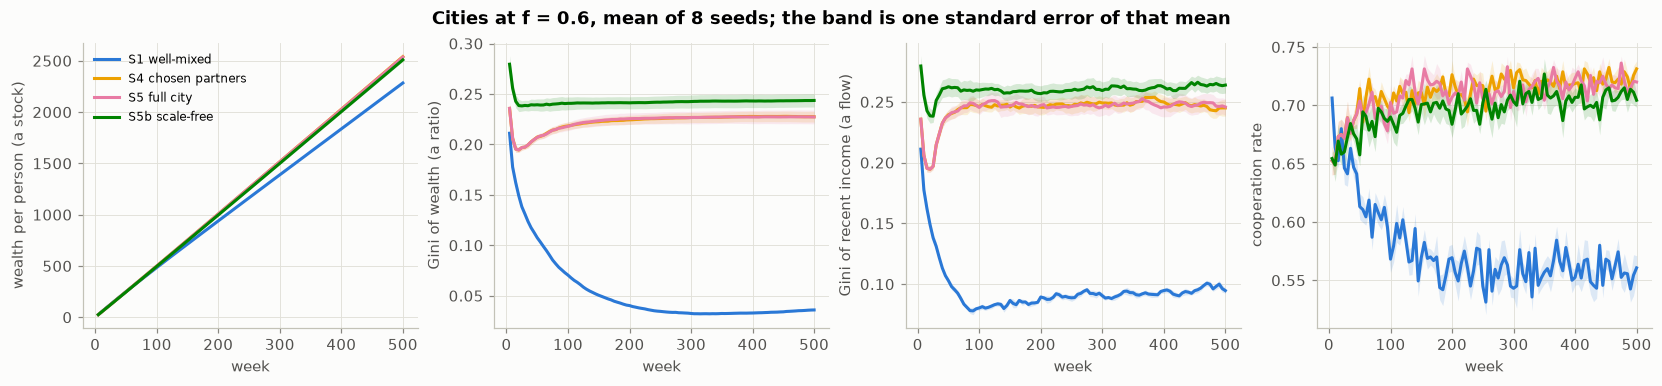

gini        income_gini        mean_wealth          
round                 250    500         250    500         250       500
scenario                                                                 
S1 well-mixed       0.035  0.036       0.089  0.095    1163.992  2283.496
S2 static network   0.170  0.169       0.182  0.186    1122.215  2240.650
S3 ties fade        0.170  0.169       0.182  0.186    1122.215  2240.650
S4 chosen partners  0.226  0.227       0.246  0.245    1261.556  2540.511
S5 full city        0.226  0.227       0.246  0.246    1261.068  2535.982
S5b scale-free      0.242  0.244       0.259  0.264    1247.862  2508.950

In [9]:
LADDER = ["S1 well-mixed", "S2 static network", "S3 ties fade", "S4 chosen partners", "S5 full city"]
SHOWN = ["S1 well-mixed", "S4 chosen partners", "S5 full city", "S5b scale-free"]

# One giver fraction at a time: averaging across the mix would blend cities that differ by design.
mid_core = sweep.core[np.isclose(sweep.core["giver_fraction"], 0.6)]
convergence = R.series_means(mid_core, ["mean_wealth", "gini", "income_gini", "coop_rate"])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
panels = [("mean_wealth", "wealth per person (a stock)"), ("gini", "Gini of wealth (a ratio)"),
          ("income_gini", "Gini of recent income (a flow)"), ("coop_rate", "cooperation rate")]
for ax, (metric, label) in zip(axes, panels):
    P.over_time(ax, convergence, metric, SHOWN, colours, ylabel=label)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Cities at f = 0.6, mean of 8 seeds; the band is one standard error of that mean",
             fontweight="bold")
plt.show()

convergence[convergence["round"].isin([250, 500])].pivot_table(
    index="scenario", columns="round", values=["mean_wealth", "gini", "income_gini"]).round(3)

**What this shows:** mean wealth doubles exactly between week 250 and week 500 in every scenario
(S5: 1,261 to 2,536), which is what a stock with a constant inflow must do. It never converges and
never will. Every other panel is flat well before the end: in S5 the Gini of wealth moves from
0.226 to 0.227 over those same 250 weeks, and the Gini of recent income does not move at all
(0.246 to 0.246).

So the cities *are* in a steady state by week 250, in the only sense the word can have here: the
rate at which wealth is produced and the unevenness of its sharing have both stopped changing.
This is also the justification for summarising flow metrics over the last 100 rounds and stocks by
their final value, which is what `summarise` does and what every table above reports.

### Where the Scenarios Diverge

The ladder is built so that each step adds exactly one mechanism, and every scenario shares its
random streams with the others for a given seed. That makes a **paired** comparison possible: for
each of the 48 cities (6 giver fractions x 8 seeds) we can take the same city under two adjacent
rule sets and difference them. What is left is the mechanism, with the luck of the draw cancelled
out.

This is the quantitative version of the S1-to-S5 story told in the results section above, and on
two points it corrects it.

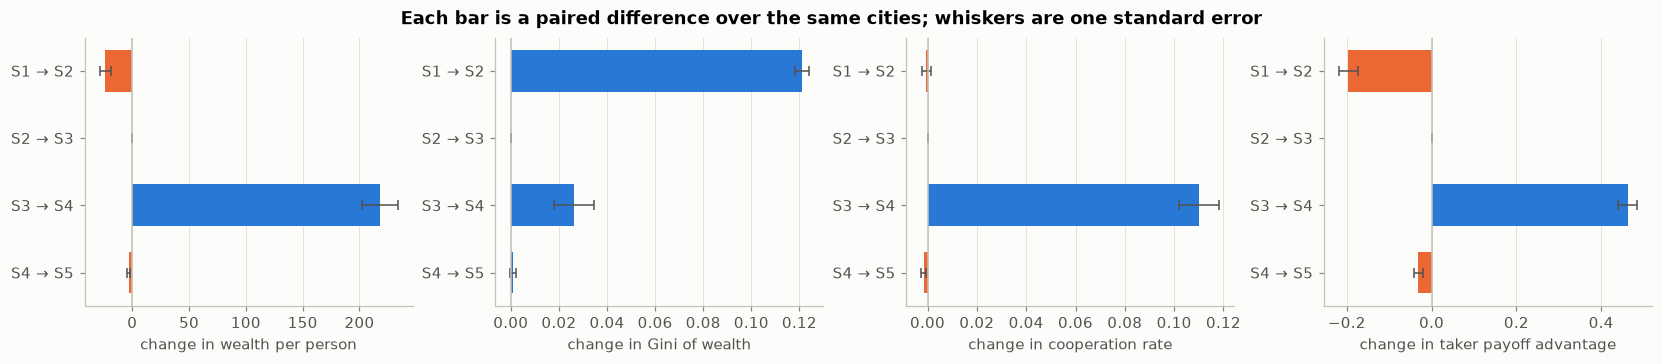

,metric,step,mean,se,n
0,mean_wealth,S1 → S2,-23.9175,4.8419,48
1,mean_wealth,S2 → S3,0.0000,0.0000,48
2,mean_wealth,S3 → S4,218.0733,15.6071,48
3,mean_wealth,S4 → S5,-3.1831,1.2802,48
0,gini,S1 → S2,0.1209,0.0029,48
1,gini,S2 → S3,0.0000,0.0000,48
2,gini,S3 → S4,0.0263,0.0081,48
3,gini,S4 → S5,0.0010,0.0011,48
0,coop_rate,S1 → S2,-0.0004,0.0018,48
1,coop_rate,S2 → S3,0.0000,0.0000,48


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
panels = [("mean_wealth", "change in wealth per person"), ("gini", "change in Gini of wealth"),
          ("coop_rate", "change in cooperation rate"), ("payoff_gap", "change in taker payoff advantage")]
deltas = {}
# payoff_gap is undefined when a class is absent, so its panel pairs 32 cities rather than 48.
for ax, (metric, label) in zip(axes, panels):
    deltas[metric] = R.stage_deltas(runs, metric, LADDER)
    P.delta_bars(ax, deltas[metric], xlabel=label)
fig.suptitle("Each bar is a paired difference over the same cities; whiskers are one standard error",
             fontweight="bold")
plt.show()

pd.concat([t.assign(metric=m) for m, t in deltas.items()])[["metric", "step", "mean", "se", "n"]].round(4)

**What this shows, and where it revises the story above:**

- **Structure redistributes without creating.** Putting the same population on a fixed network
  (S1 to S2) raises the Gini by 0.121 and *lowers* wealth per person slightly (-23.9). The taker
  payoff advantage does fall, by 0.196 per game, which is network reciprocity working as expected.
  But the cooperation rate does not move at all: -0.0004, with a standard error of 0.0018. The
  results section above reads this step as reciprocal strategies punishing takers, and that is
  right about *who wins*; it is wrong to imply the city becomes more cooperative. It does not.
  Network reciprocity here changes the distribution of a fixed amount of cooperation.

- **Choice is where almost everything happens.** S3 to S4 adds +218 to wealth per person, +0.110
  to the cooperation rate, +0.026 to the Gini and -0.114 to class assortativity. Every headline
  result in this project is produced by this one step. It also *reverses* the taker payoff
  advantage, adding back 0.462 per game: once meetings are chosen, takers are sought out by
  highly rated givers who cannot refuse them.

- **S2 to S3 is exactly zero on every measure.** Not approximately: the paired difference and its
  standard error are both 0.0000, because no tie in any S3 city ever decays past the severance
  threshold. Decay is a real mechanism that does nothing at these parameters, which is worth
  stating plainly rather than presenting as a scenario that was tested and found similar.

- **Rewiring repairs rather than redistributes.** S4 to S5 moves wealth by -3.2 and the Gini by
  +0.001, neither distinguishable from zero, while it returns +0.072 of class assortativity, a
  little over half of what the previous step removed.

### Clustering and Connectivity

H2 argues that inequality does not fall with cooperation partly because "cooperation relies on
clusters". Up to this point that claim was carried entirely by the citations: no measurement in
this notebook says anything about clustering. Two coefficients fix that.

**Average clustering** is the mean over citizens of the share of their acquaintance pairs who
also know each other, so it reports the typical citizen. **Transitivity** is closed triples over
all triples across the whole city, which weights by degree and so reports the city. They are
tracked every 10 weeks alongside the mean shortest path and the number of components.

Because ties break and reform only through mechanisms we control, any movement in these
coefficients is attributable: capacity is pinned at each agent's starting degree, so the city
cannot simply acquire more ties.

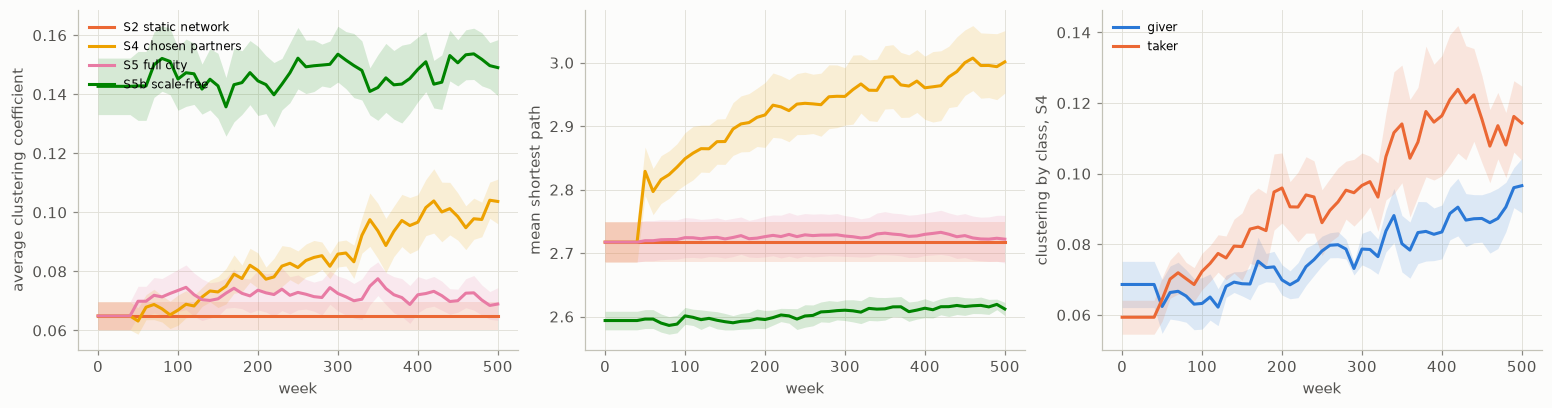

,clustering vs cooperation,clustering vs Gini,components at the end
scenario,,,
S4 chosen partners,0.056,-0.057,1.219
S5 full city,0.111,0.078,1.000
S5b scale-free,0.086,0.229,1.000


In [11]:
mid_structure = sweep.structure[np.isclose(sweep.structure["giver_fraction"], 0.6)]
structure_ts = R.series_means(mid_structure, ["clustering", "clustering_giver", "clustering_taker",
                                              "transitivity", "mean_path_length", "n_components"])
NETWORKS = ["S2 static network", "S4 chosen partners", "S5 full city", "S5b scale-free"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
P.over_time(axes[0], structure_ts, "clustering", NETWORKS, colours,
            ylabel="average clustering coefficient")
P.over_time(axes[1], structure_ts, "mean_path_length", NETWORKS, colours,
            ylabel="mean shortest path")
s4 = structure_ts[structure_ts["scenario"] == "S4 chosen partners"].sort_values("round")
for column, label in [("clustering_giver", "giver"), ("clustering_taker", "taker")]:
    P.band(axes[2], s4["round"], s4[column], s4[column] - s4[f"{column}_se"],
           s4[column] + s4[f"{column}_se"], P.CLASS_COLOURS[label], label=label)
axes[2].set(xlabel="week", ylabel="clustering by class, S4")
axes[0].legend(fontsize=8, loc="upper left")
axes[2].legend(fontsize=8)
plt.show()

mixed_runs = runs[runs["giver_fraction"].between(0.15, 0.85)]
pd.DataFrame([{"scenario": s,
               "clustering vs cooperation": metrics.spearman(q["clustering"], q["coop_rate"]),
               "clustering vs Gini": metrics.spearman(q["clustering"], q["gini"]),
               "components at the end": q["n_components"].mean()}
              for s in ["S4 chosen partners", "S5 full city", "S5b scale-free"]
              for q in [mixed_runs[mixed_runs["scenario"] == s]]]).set_index("scenario").round(3)

**What this shows:**

- **Severance concentrates, rewiring restores reach.** In S4, where ties break and are never
  replaced, clustering rises from 0.065 to 0.104 and the mean shortest path stretches from 2.72
  to 3.00 as the city begins to fragment (about 1.2 components on average). The surviving ties are the
  used ones, and used ties are local. In S5 the same severance happens but refilled ties are drawn
  from distance 2 and 3, so clustering barely moves (0.065 to 0.069), the path length holds at
  2.72, and the city stays in one piece. Rewiring buys connectivity at the cost of the local
  concentration that severance was producing.

- **H2's clustering premise is not supported here.** Across mixed cities the rank correlation
  between clustering and the cooperation rate is +0.06 in S4, +0.11 in S5 and +0.09 in S5b. Nothing
  in these runs suggests that cooperation depends on clusters, and the argument for H2 should rest
  on access and status, which the decomposition above does support, rather than on clustering,
  which it does not. On the scale-free network clustering does track inequality (+0.23), which is
  a different claim.

- **Takers sit in denser neighbourhoods than givers**, in every scenario (S4: 0.114 against 0.097).
  This is very likely an artefact rather than a finding: the clustering coefficient divides by
  `k(k-1)`, and takers hold fewer ties, which mechanically raises the ratio. It should not be read
  as takers forming cliques without a degree-matched comparison, which we have not run.

### Inequality Without Exploitation

The Lorenz curves earlier showed something that deserves more than a passing note: a city where
**every** citizen plays Tit-for-Tat, and where no game is ever exploited, is almost exactly as
unequal as a mixed city. Two explanations were offered in the group: that some citizens fall into
positively reinforced relationships early, and that others become trapped in mutually punishing
ones.

The second cannot be true in a TFT-only city. Tit-for-Tat opens with cooperation and mirrors
afterwards, so two TFT agents cooperate forever and never defect once. There are no punishing
relationships to fall into. That turns out to make the test sharper rather than spoiling it: if
every move is cooperative, then each game pays exactly `R = 3` to both players, and

$$ \text{wealth}_i = 3 \times \text{games played}_i $$

exactly. Inequality of wealth *is* inequality of attention, with nothing else mixed in. So we can
ask where the attention goes by switching off the two feedback channels in the choice rule, one at
a time: habit ($\beta$, the weight on an existing tie) and status ($\gamma$, the weight on the
partner's rating).

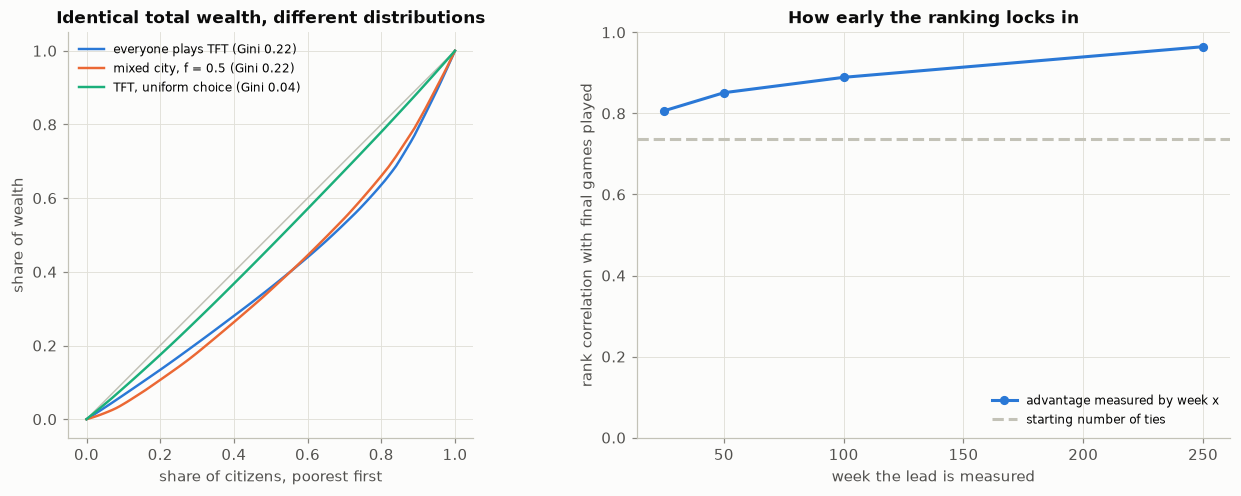

every move cooperative, so wealth is exactly three times games played: True


,scenario,gini,mean_wealth,gini_se,mean_wealth_se
0,full: habit x status,0.2107,3000.0,0.0033,0.0
1,habit only,0.0525,3000.0,0.0004,0.0
2,neither: uniform,0.0496,3000.0,0.0031,0.0
3,status only,0.1337,3000.0,0.0034,0.0


In [12]:
CHOICE_VARIANTS = {
    "full: habit x status": ("M4", {}),
    "status only":          ("M4", {"encounter.weight_exponent": 0.0}),
    "habit only":           ("M4", {"encounter.popularity_exponent": 0.0}),
    "neither: uniform":     ("M4", {"encounter.weight_exponent": 0.0, "encounter.popularity_exponent": 0.0}),
}
ALL_TFT = {"population.giver_composition": {"tft": 1.0}}
tft_runs = R.sweep(CHOICE_VARIANTS, [1.0], n_seeds=6, **{**SETTINGS, **ALL_TFT})
decomposition = R.cell_means(tft_runs, ["gini", "mean_wealth"], by=("scenario",))

curves, curve_ginis = {}, {}
for label, overrides in [("everyone plays TFT", {**ALL_TFT, "population.giver_fraction": 1.0}),
                         ("mixed city, f = 0.5", {"population.giver_fraction": 0.5}),
                         ("TFT, uniform choice", {**ALL_TFT, "population.giver_fraction": 1.0,
                                                  "encounter.weight_exponent": 0.0,
                                                  "encounter.popularity_exponent": 0.0})]:
    sim = Simulation(stage("M4", **{**SETTINGS, **overrides}), root_seed=R.DEFAULT_SEED,
                     repeat=0, instruments=("core",))
    sim.run()
    curves[label], curve_ginis[label] = metrics.lorenz(sim.state.wealth), metrics.gini(sim.state.wealth)

# Does an early lead survive? Rank citizens by games played at several points, against the end.
watch = Simulation(stage("M4", **{**SETTINGS, **ALL_TFT, "population.giver_fraction": 1.0}),
                   root_seed=R.DEFAULT_SEED, repeat=1, instruments=("core",))
marks = {}
for _ in range(SETTINGS["run.n_rounds"]):
    watch.run_round()
    if watch.state.t in (25, 50, 100, 250):
        marks[watch.state.t] = watch.state.games_played.copy()
final_games = watch.state.games_played

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
P.lorenz_curves(axes[0], curves, ginis=curve_ginis)
axes[0].legend(fontsize=8, loc="upper left")
axes[0].set_title("Identical total wealth, different distributions")
weeks = sorted(marks)
axes[1].plot(weeks, [metrics.spearman(marks[w], final_games) for w in weeks],
             color=P.SERIES[0], marker="o", label="advantage measured by week x")
axes[1].axhline(metrics.spearman(watch.state.capacity, final_games), color=P.AXIS,
                linestyle="--", label="starting number of ties")
axes[1].set(xlabel="week the lead is measured", ylabel="rank correlation with final games played",
            ylim=(0, 1), title="How early the ranking locks in")
axes[1].legend(fontsize=8, loc="lower right")
plt.show()

print(f"every move cooperative, so wealth is exactly three times games played: "
      f"{np.allclose(watch.state.wealth, 3.0 * final_games)}")
decomposition.round(4)

**What this shows:**

| Partner choice, everyone plays TFT | Gini | Wealth per person |
|---|---|---|
| Full: habit x status | 0.211 | 3,000 |
| Status only | 0.134 | 3,000 |
| Habit only | 0.053 | 3,000 |
| Neither: uniform | 0.050 | 3,000 |

**Wealth per person is identical to the unit in all four.** Every citizen plays the same number of
games in total across the city, and every game pays 3 to each side, so the total is fixed by the
rules. The only thing that varies is who gets them, and that alone moves the Gini from 0.050 to
0.211, a factor of four.

**Status is the channel that does it.** Removing status collapses inequality almost to the uniform
baseline (0.053 against 0.050); removing habit leaves most of it standing (0.134). Yet the two
together produce far more than they do apart (+0.161 over baseline, against +0.084 and +0.003
separately). They compound because the rating is a product of cooperativeness and *relative tie
strength*: habit builds the strength that status then rewards, and status directs the meetings
that build more strength.

**And the ranking locks in early.** The rank correlation between games played by week 25 and games
played at week 500 is +0.81, rising to +0.97 by week 250. A citizen's starting number of ties
predicts the final count at +0.74 on its own. So the answer to the original question is: yes, some
citizens do get into positively reinforced relationships early, and the advantage is close to
permanent by the time the city is a tenth of the way through its life. No exploitation is
required, and none occurs.

This is the sharpest statement of the project's central conclusion. A TFT-only city reaches a Gini
of 0.215 and a mixed city 0.223 — nearly the same inequality from completely different moral
material. **Inequality here is positional, not extractive.** The Lorenz curve of a city where
nobody can be cheated looks like the Lorenz curve of one where half the population cheats,
because in both the binding constraint is who gets met.

### Example Cities

Everything above is an average over seeds. This last figure is not evidence and is not used to
support any claim; it is here to show what the mechanisms look like on a single small city, at a
size where individual citizens can be picked out.

The top row follows one 40-citizen city through its life. The bottom row shows four different
seeds at the same final week, which is the honest caveat: at this size the structure is noisy, and
any one picture would mislead if read as typical.

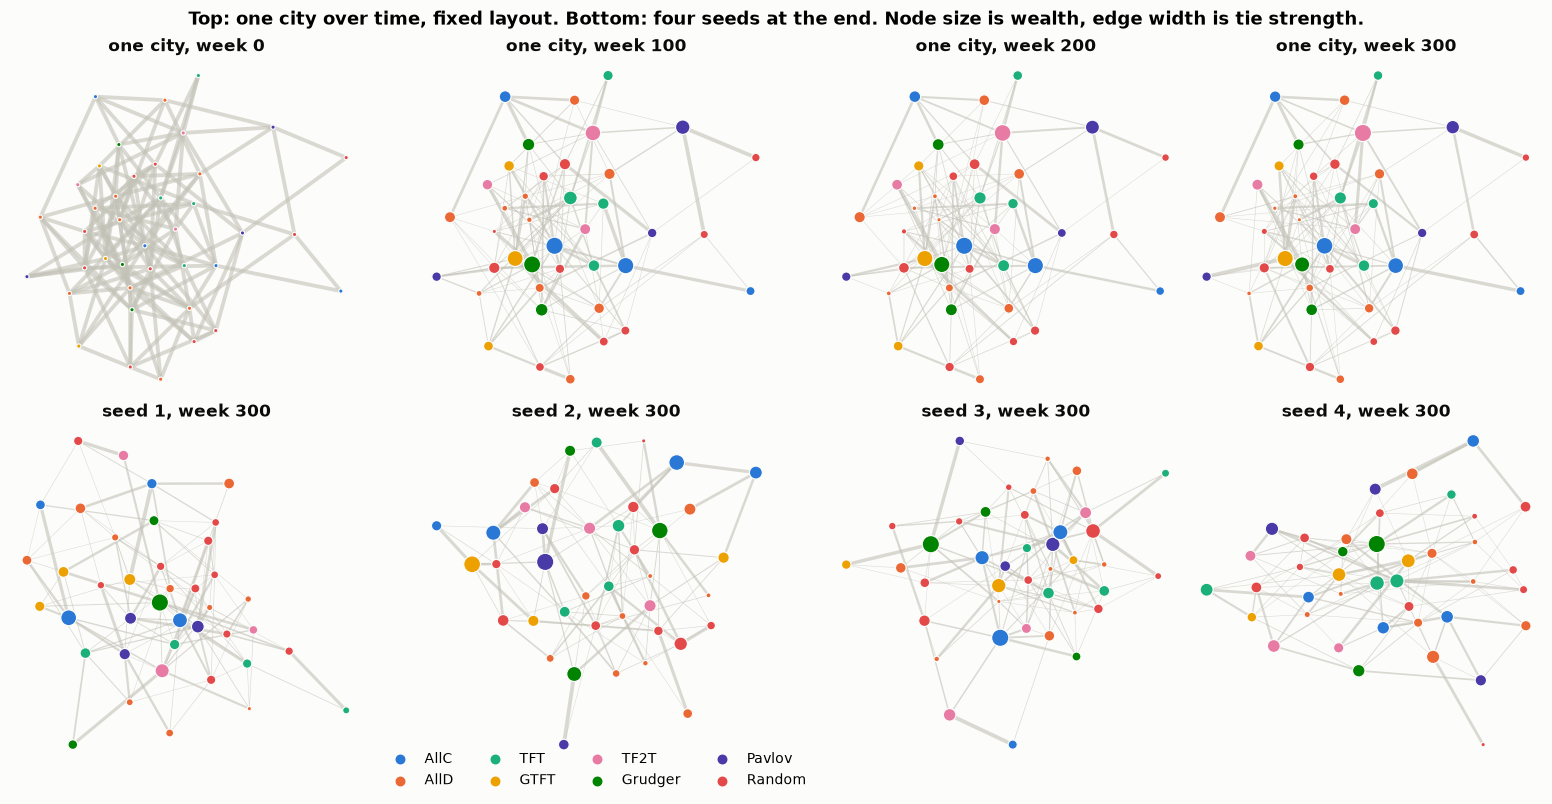

In [13]:
from utilities.network_draw import draw_snapshot, layout, strategy_legend

DEMO = {"population.n_agents": 40, "run.n_rounds": 300, "population.giver_fraction": 0.5}
demo = Simulation(stage("M4", **DEMO), root_seed=R.DEFAULT_SEED, repeat=0, instruments=("snapshots",))
frames = {frame["round"]: frame for frame in demo.run().outputs["snapshots"]}
pos = layout(frames[0]["adjacency"], seed=3)   # fixed positions, so ties can be seen moving

fig, axes = plt.subplots(2, 4, figsize=(14, 7.2))
for ax, week in zip(axes[0], [0, 100, 200, 300]):
    draw_snapshot(ax, frames[week], pos, title=f"one city, week {week}")
for ax, repeat in zip(axes[1], range(1, 5)):
    other = Simulation(stage("M4", **DEMO), root_seed=R.DEFAULT_SEED, repeat=repeat,
                       instruments=("snapshot",))
    snap = other.run().outputs["snapshot"]
    draw_snapshot(ax, snap, layout(snap["adjacency"], seed=3), title=f"seed {repeat}, week 300")
strategy_legend(axes[1][1])
fig.suptitle("Top: one city over time, fixed layout. Bottom: four seeds at the end. "
             "Node size is wealth, edge width is tie strength.", fontweight="bold")
plt.show()

**What to look for:** node size is accumulated wealth and edge width is tie strength, so the top
row shows a city that starts uniform and ends with a handful of thick, heavily used relationships
and a periphery of thin ones. The takers (orange, red) are not pushed to the edge of the drawing,
which is the point made in the results: they keep their ties to givers, and it is the ties
*between* takers that fade.

The bottom row is the reason this is illustrative only. Four cities under identical rules, and
the eye finds a different story in each.

## Conclusions

- **More givers make a city richer, and the gain accelerates:** prosperity is set by how often givers meet each other, not by how many there are, so wealth per person bends upwards once givers pass about 30% of the city.

- **Prosperity and equality come apart:** inequality peaks in mixed cities rather than falling steadily as cooperation rises. On a scale-free network it stays high in the richest cities, because hubs capture the surplus. This runs against network-game results that report inequality falling with cooperation [4], and it does so through a mechanism those models do not have: who you can meet.

- **Inequality here is positional, not extractive:** a city where every citizen plays Tit-for-Tat, and where no game is ever exploited, reaches a Gini of 0.215 against a mixed city's 0.223. Total wealth is identical however partners are chosen; only its distribution moves, and removing the status term from the choice rule collapses the Gini to 0.05. The rank order of who gets met is settled by week 25 and effectively fixed by week 250.

- **The clustering premise behind H2 is not supported by these runs:** clustering and the cooperation rate are essentially uncorrelated across mixed cities (Spearman +0.06 to +0.11). The case for H2 rests on access and status, which the decomposition does support, and not on clusters, which it does not.

- **Structure, not strategy, decides the distribution:** the same population produces near-equality when well-mixed and marked inequality once meetings are constrained by network, habit and status. Each restriction on access raises inequality; none of them changes anybody's strategy.

- **Segregation emerges, but not the kind we predicted:** takers end up with fewer partners and weaker ties without any rule that excludes them. Yet the city becomes *disassortative*: takers keep seeking out givers, who cannot refuse, while ties between takers fade from disuse.

- **Poor cities are equally poor:** taker-dominated cities have low median wealth and low inequality, so median wealth separates a good city from a bad one better than a Gini coefficient does.

## Limitations and Future Work

### Limitations

- **Eight seeds and 100 agents:** enough to establish the ordering of the scenarios, not enough for the strict 99% criteria in H2, and small cities have noisier structure than large ones.
- **Fixed strategies:** nobody learns, imitates a richer neighbour, or changes class. The mix is an input, not an outcome.
- **No refusal and no memory of reputation beyond one number:** a giver cannot decline a known defector. The disassortative networks depend on this.
- **Wealth only accumulates:** there is no spending, investment, inheritance or subsistence cost in these runs, so accumulated wealth keeps growing and its Gini is measured on a stock that never resets.
- **Closed cities:** no birth, death or migration, and every city starts from one generated network per seed.

### Future work

1. **Let strategies spread:** allow agents to imitate more successful neighbours. The interesting question is whether a city that starts above the prosperity threshold pulls itself up, and whether an unequal but rich city is stable.
2. **Give citizens the right to refuse:** allowing a giver to decline a known defector is the single change most likely to turn the disassortative network assortative, and it would test whether H3 fails because of the mechanism or because of this one missing rule.
3. **Spend the wealth:** a subsistence cost and an investment channel would make poverty absorbing rather than merely slow, which is closer to the phenomenon the model is aimed at.
4. **Calibrate against data:** cross-class connectedness and mobility have been measured at scale [2]; matching the model's tie distribution and mobility to that data would turn the qualitative comparisons here into quantitative ones.

## References

[1] X. Xue, W. R. Reed, and R. C. M. van Aert, "Social capital and economic growth: A meta-analysis," *Journal of Economic Surveys*, vol. 39, pp. 1395-1432, Sep. 2025, doi: 10.1111/joes.12660.

[2] R. Chetty et al., "Social capital I: Measurement and associations with economic mobility," *Nature*, vol. 608, no. 7921, pp. 108-121, Aug. 2022, doi: 10.1038/s41586-022-04996-4.

[3] A. B. Downey, *Think Complexity: Complexity Science and Computational Modeling*, 2nd ed. Sebastopol, CA, USA: O'Reilly Media, 2018.

[4] L.-L. Jiang, Y.-M. Li, W.-J. Li, and A. Szolnoki, "Combined effect of incentives and coupling in multigames in two-layer networks," *Journal of Physics: Complexity*, vol. 6, no. 1, Art. no. 015003, Mar. 2025, doi: 10.1088/2632-072X/ada844.

[5] M. Tsvetkova, "The effects of reputation on inequality in network cooperation games," *Philosophical Transactions of the Royal Society B*, vol. 376, no. 1838, Art. no. 20200299, Nov. 2021, doi: 10.1098/rstb.2020.0299.

[6] M. Tsvetkova, C. Wagner, and A. Mao, "The emergence of inequality in social groups: Network structure and institutions affect the distribution of earnings in cooperation games," *PLOS ONE*, vol. 13, no. 7, Art. no. e0200965, Jul. 2018, doi: 10.1371/journal.pone.0200965.

[7] A. Nishi, H. Shirado, D. G. Rand, and N. A. Christakis, "Inequality and visibility of wealth in experimental social networks," *Nature*, vol. 526, no. 7573, pp. 426-429, Oct. 2015, doi: 10.1038/nature15392.

[8] M. A. Nowak and R. M. May, "Evolutionary games and spatial chaos," *Nature*, vol. 359, no. 6398, pp. 826-829, Oct. 1992, doi: 10.1038/359826a0.

[9] D. Melamed, A. Harrell, and B. Simpson, "Cooperation, clustering, and assortative mixing in dynamic networks," *Proceedings of the National Academy of Sciences*, vol. 115, no. 5, pp. 951-956, Jan. 2018, doi: 10.1073/pnas.1715357115.

[10] J. Szüle, D. Kondor, L. Dobos, I. Csabai, and G. Vattay, "Lost in the city: Revisiting Milgram's experiment in the age of social networks," *PLOS ONE*, vol. 9, no. 11, Art. no. e111973, Nov. 2014, doi: 10.1371/journal.pone.0111973.

[11] W. Ahmad, M. A. Porter, and M. Beguerisse-Díaz, "Tie-decay networks in continuous time and eigenvector-based centralities," *IEEE Transactions on Network Science and Engineering*, vol. 8, no. 2, pp. 1759-1771, Apr. 2021, doi: 10.1109/TNSE.2021.3071429.

[12] V. M. R. Muggeo, "Estimating regression models with unknown break-points," *Statistics in Medicine*, vol. 22, no. 19, pp. 3055-3071, Oct. 2003, doi: 10.1002/sim.1545.

[13] A. E. Raftery, "Bayesian model selection in social research," *Sociological Methodology*, vol. 25, pp. 111-163, 1995, doi: 10.2307/271063.

[14] B. Efron, "Bootstrap methods: Another look at the jackknife," *The Annals of Statistics*, vol. 7, no. 1, pp. 1-26, Jan. 1979, doi: 10.1214/aos/1176344552.